# 5. Lake Sibaya tTEM with bathymetry

The March 2023 Sibaya tTEM/floaTEM data inverted with pyTEM, using the lake-bed survey (PID) and a DEM so that the inversion can make a sharp jump at the lake bottom.

1. Read the Workbench per-channel export with its `.gex`; each LM row is joined with the HM row recorded just after it (one station).
2. Combine the DEM (Copernicus GLO-30, land) and the bathymetry (PID, lake bed) into one surface and plot it.
3. Water depth at each station = lake level − lake-bed elevation. The two basins are separate lakes since about 2012 and have very different levels during the survey (main basin about 15.8 m, southern basin about 9.4 m): the main basin takes the daily SAEON record on the survey day of the station, the southern basin its own monthly gauge, interpolated to that day. Where the lake bed of the bathymetry is above the lake level (the lake has retreated) the station is on land. The DEM over the water is not the lake level.
4. Invert a line with one layer boundary at the lake bed and no vertical smoothing across it, so the water and the sediment below can differ sharply while both resistivities are still inverted.

In [1]:
import os
from pathlib import Path

SIBAYA = Path(r"C:\Users\pamcl\OneDrive - Danmarks Tekniske Universitet\Dokumenter\Projects_Sorted\Current\SouthAfrica\Sibaya")
PROCESSED, UNSORTED = SIBAYA / "processed", SIBAYA / "unsorted" / "Sibaya"
DAYS = ("230317", "20230318", "20230321", "230323", "230324", "20230325")   # the survey days; one Workbench per-channel export (DBDT_ChNGTn columns) each
DATA = [PROCESSED / f"{day}_RAW_export.xyz" for day in DAYS]
DEM = PROCESSED / "Copernicus_DSM_COG_10_S28_00_E032_00_DEM.tif"   # Copernicus GLO-30; downloaded below if missing
GEX = UNSORTED / "Data" / "Sabayi_tTEM_2023.gex"                    # system, from the Workbench .tem files
BATHY = UNSORTED / "PID_bathy_data-20240604T075512Z-001" / "PID_bathy_data" / "gisdata" / "geotiff_utm.tif"   # lake-bed elevation [m]

LAKE_RECORD = UNSORTED / "Lake Levels" / "SAEON adjusted record  20241002 for Paul.xlsx"   # daily level [m asl] of the main basin: columns Date, final
LAKE_MONTHLY = UNSORTED / "Lake Levels" / "Lake level 202406 Monthly.xlsx"   # monthly levels, with the gauge of the southern basin (a separate lake since about 2012)
PROFILER = Path(r"C:\Users\pamcl\OneDrive - Danmarks Tekniske Universitet\Dokumenter\Projects\Python\profiler\src")   # GeoProfiler: draws the sections
LAKE_OFFSET = {"north": 0.0, "south": 0.0}   # added to the recorded level of each basin [m]
LAKE_LEVEL = {"north": None, "south": None}   # a fixed lake surface [m asl] for a basin; None: the daily record of the main basin / the gauge of the southern basin on the survey day
SPLIT_N = None         # UTM northing [m] between the north and south basins; None: the median northing of the lake stations
BED_BREAK = True       # no vertical smoothing across the lake bed
LINE = None            # line to invert; None: the line with most stations on the lake
STEP = 20              # invert every STEP-th station of the line (1: all stations)
WORKERS = os.cpu_count()   # parallel CPU (numba) threads for the inversion
GPU_WORKERS = 1        # extra threads on the GPU (CuPy) if CUDA is available; 0: CPU only
N_LAYERS, FIRST, BOTTOM = 25, 1.0, 100.0   # layer grid: first layer [m] and depth of the half-space top [m]
CELL = 20.0            # cell size of the combined DEM/bathymetry map [m]

In [2]:
import os, queue, sys, threading, time, urllib.request
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import contextily as ctx
import rasterio
from rasterio.vrt import WarpedVRT
from pyproj import Transformer

for _root in [Path.cwd(), *Path.cwd().parents]:
    if (_root / "pytem").is_dir():
        sys.path.insert(0, str(_root))
        break
import pytem.inversion as pinv
from pytem import invert_joint
from pytem.data_io import read_workbench_xyz
from pytem.waveform import setup_shared_gate_matrices
from pytem.system_filter import butterworth_filter

sys.path.insert(0, str(PROFILER))
from profiler.profiler import Plot

def section(ax, dists, rhos, bottoms, elev, doi=None, base=120.0, **kwargs):
    """A resistivity section with GeoProfiler's Plot.plot2D: soundings at ``dists`` [m] (each drawn from the middle to the middle
    of its neighbours), ``rhos`` (n, L) [Ohm m], ``bottoms`` (n, L-1) the depths of the layer bottoms of every sounding, ``elev`` (n)
    the top of the model [m], ``doi`` (n) its depth of investigation [m]. plot2D draws the first column of ``rhos`` with no
    thickness and drops the last sounding, so a copy of both is added here. kwargs: plot2D's (vmin, vmax, cmap, scale, zmin...)."""
    dists, rhos, bottoms, elev = (np.asarray(a, dtype=float) for a in (dists, rhos, bottoms, elev))
    n = len(dists)
    edges = np.r_[dists[0] - 0.5 * (dists[1] - dists[0]), 0.5 * (dists[1:] + dists[:-1]), dists[-1] + 0.5 * (dists[-1] - dists[-2])]
    pad = lambda a: np.concatenate([a, a[-1:]])
    rhos = pad(rhos)
    doi = None if doi is None else pad(np.where(np.isfinite(doi), doi, 10 * base))
    kwargs = {**dict(vmin=1, vmax=1000, scale=10, xmin=edges[0], xmax=edges[-1], zmin=np.nanmin(elev) - base, zmax=np.nanmax(elev)), **kwargs}
    Plot(None).plot2D(np.c_[rhos[:, 0], rhos], np.c_[pad(bottoms), np.full(n + 1, base)], elev=pad(elev), dists=edges, doi=doi, ax=ax, **kwargs)

tems = [read_workbench_xyz(path, GEX) for path in DATA]   # same system (.gex) for every day, so the first one carries the metadata
tem = tems[0]
tem.data = pd.concat([t.data for t in tems], ignore_index=True)
meta = tem.meta
system = {m: dict(times=g["center"], gate_open=g["open"], gate_close=g["close"],
                  waveform_times=tem.waveforms[m]["time"], waveform_currents=tem.waveforms[m]["amplitude"])
          for m, g in tem.gate_times.items()}
t_step, M = setup_shared_gate_matrices(system)
tx_radius = np.sqrt(meta["LoopX"] * meta["LoopY"] / np.pi)      # equal-area circle: much faster than the square loop
rx_offset = np.hypot(meta["RXcoil_X_Position"], meta["RXcoil_Y_Position"])
H = lambda w: np.prod([butterworth_filter(f_high=f)(w) for f in meta["LowPass"]], axis=0)   # the .gex low-pass filters

# One station = an LM row and the HM row recorded just after it on the same line (about 0.46 s later)
d = tem.data.assign(t=pd.to_datetime(tem.data["Date"] + " " + tem.data["Time"]).astype("int64") / 1e9)
is_lm = d["LMcurrent"].notna().to_numpy()
nxt = np.r_[np.arange(1, len(d)), 0]
paired = is_lm & ~is_lm[nxt] & (d["Line"].to_numpy() == d["Line"].to_numpy()[nxt]) & (d["t"].to_numpy()[nxt] - d["t"].to_numpy() < 1.0)
lm_rows = np.flatnonzero(paired)
hm_rows = nxt[lm_rows]
stations = d.iloc[lm_rows][["Line", "Date", "E", "N", "Elevation"]].reset_index(drop=True)
print(f"{len(stations)} stations (LM + HM) from {len(d)} rows; loop {meta['LoopX']} m (radius {tx_radius:.2f} m), Rx at {rx_offset:.2f} m")

49156 stations (LM + HM) from 98687 rows; loop 2.9 m (radius 1.64 m), Rx at 9.00 m


## DEM and bathymetry combined

In [3]:
x, y = stations["E"].to_numpy(), stations["N"].to_numpy()

def sample(path):
    """Raster values at the stations (NaN outside or on nodata)."""
    with rasterio.open(path) as src:
        px, py = Transformer.from_crs("EPSG:32736", src.crs, always_xy=True).transform(x, y)
        return np.array([v.filled(np.nan)[0] for v in src.sample(zip(px, py), masked=True)], float)

def on_grid(path, transform, shape):
    """A raster resampled to the UTM 36S map grid (only the part under the grid is read)."""
    with rasterio.open(path) as src, WarpedVRT(src, crs="EPSG:32736", transform=transform, width=shape[1], height=shape[0], resampling=rasterio.enums.Resampling.bilinear) as vrt:
        return vrt.read(1, masked=True).astype(float).filled(np.nan)

if not DEM.exists():   # Copernicus GLO-30 tile (1x1 degree) from the public AWS bucket
    lon, lat = Transformer.from_crs("EPSG:32736", "EPSG:4326", always_xy=True).transform(np.mean(x), np.mean(y))
    tile = f"Copernicus_DSM_COG_10_{'S' if lat < 0 else 'N'}{abs(int(np.floor(lat))):02d}_00_{'W' if lon < 0 else 'E'}{abs(int(np.floor(lon))):03d}_00_DEM"
    urllib.request.urlretrieve(f"https://copernicus-dem-30m.s3.amazonaws.com/{tile}/{tile}.tif", DEM)

# At the stations: lake bed where there is bathymetry, the DEM elsewhere
bed, ground = sample(BATHY), sample(DEM)
on_lake = np.isfinite(bed)
split = np.median(y[on_lake]) if SPLIT_N is None else SPLIT_N
basin = np.where(y >= split, "north", "south")
record = pd.read_excel(LAKE_RECORD, dtype=object)   # the column 'final' holds text such as 'nil' in places
record = pd.DataFrame({"Date": pd.to_datetime(record["Date"], errors="coerce"), "final": pd.to_numeric(record["final"], errors="coerce")}).dropna()
dates, previous = [], None   # about 2000 dates were typed dd/mm/yyyy and read as mm/dd/yyyy: swap them back where that gives the day after the previous row
for date in record["Date"]:
    if previous is not None and date != previous + pd.Timedelta(days=1) and date.day <= 12:
        swapped = pd.Timestamp(year=date.year, month=date.day, day=date.month)
        date = swapped if swapped == previous + pd.Timedelta(days=1) else date
    dates.append(date)
    previous = date
level_north = record.assign(Date=dates).groupby("Date")["final"].median().sort_index()
monthly_levels = pd.read_excel(LAKE_MONTHLY)
monthly_levels.index = pd.to_datetime(monthly_levels["yyyy/mm"].str.replace("/", "-") + "-15", errors="coerce")
gauge_south = monthly_levels["South basin"].dropna()

def level_on(series, dates, max_gap_days):
    """Level on the dates by linear interpolation between the observations; NaN when the nearest observation is more than max_gap_days away."""
    days = lambda index: ((pd.DatetimeIndex(index) - pd.Timestamp("1970-01-01")) / pd.Timedelta(days=1)).to_numpy()
    t, observed = days(dates), days(series.index)
    return np.where(np.abs(t[:, None] - observed[None, :]).min(axis=1) <= max_gap_days, np.interp(t, observed, series.values, left=np.nan, right=np.nan), np.nan)

survey_dates = pd.DatetimeIndex(pd.to_datetime(stations["Date"]))
survey_days = survey_dates.unique()
day_level = {b: pd.Series(level_on(series, survey_days, gap), index=survey_days).reindex(survey_dates).to_numpy(float)   # level of the basin on the survey day of each station
             for b, series, gap in (("north", level_north, 3), ("south", gauge_south, 45))}
print(pd.DataFrame({b: day_level[b] for b in day_level}, index=survey_dates).groupby(level=0).first().round(2).rename_axis("survey day").to_string())
lake_level, levels = np.full(len(stations), np.nan), {}
for b in ("north", "south"):
    in_basin = basin == b
    lake = on_lake & in_basin
    lake_level[in_basin] = (day_level[b] + LAKE_OFFSET[b])[in_basin] if LAKE_LEVEL[b] is None else LAKE_LEVEL[b]
    levels[b] = np.nanmedian(lake_level[in_basin])
    dry = (lake & ~(lake_level - bed > 0)).sum()
    print(f"{b} basin (N {'>=' if b == 'north' else '<'} {split:.0f} m): {lake.sum()} stations on the bathymetry, lake level {levels[b]:.2f} m asl, {dry} of them dry (lake bed above the lake level)")
print("stations without a recorded level:", int(np.isnan(lake_level).sum()))
water_depth = np.where(on_lake, lake_level - bed, np.nan)
water_depth[water_depth <= 0] = np.nan
surface = np.where(on_lake, bed, ground)                       # combined: lake bed / land
top = np.where(np.isfinite(water_depth), lake_level, ground)   # top of the TEM model: the lake level on the water, the DEM on land

# The same on a map grid around the stations
x0, x1, y0, y1 = x.min() - 1000, x.max() + 1000, y.min() - 1000, y.max() + 1000
shape = (int((y1 - y0) / CELL), int((x1 - x0) / CELL))
grid_transform = rasterio.transform.from_origin(x0, y1, CELL, CELL)
bathy_map, dem_map = on_grid(BATHY, grid_transform, shape), on_grid(DEM, grid_transform, shape)
combined = np.where(np.isfinite(bathy_map), bathy_map, dem_map)

            north  south
survey day              
2023-03-17  15.83   9.39
2023-03-18  15.83   9.40
2023-03-21  15.83   9.43
2023-03-23  15.84   9.46
2023-03-24  15.84   9.47
2023-03-25  15.85   9.48
north basin (N >= 6969757 m): 20140 stations on the bathymetry, lake level 15.84 m asl, 5066 of them dry (lake bed above the lake level)
south basin (N < 6969757 m): 20139 stations on the bathymetry, lake level 9.46 m asl, 7655 of them dry (lake bed above the lake level)
stations without a recorded level: 0


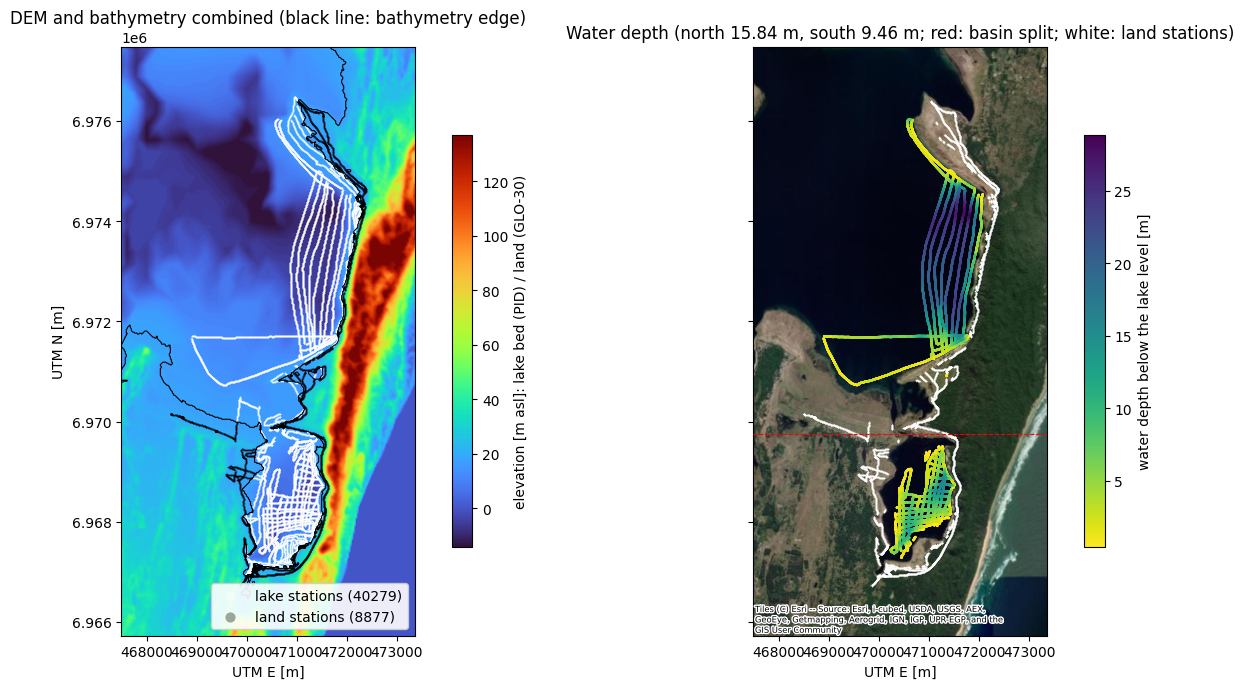

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
extent = (x0, x0 + shape[1] * CELL, y1 - shape[0] * CELL, y1)
im = a1.imshow(combined, extent=extent, cmap="turbo", vmin=np.nanpercentile(combined, 1), vmax=np.nanpercentile(combined, 99))
a1.contour(np.isfinite(bathy_map), levels=[0.5], extent=extent, origin="upper", colors="k", linewidths=0.8)
fig.colorbar(im, ax=a1, label="elevation [m asl]: lake bed (PID) / land (GLO-30)", shrink=0.7)
# stations as small semi-transparent dots, so that the topography stays visible: white on the lake, black on land
a1.scatter(x[on_lake], y[on_lake], s=1.5, c="w", alpha=0.35, linewidths=0, label=f"lake stations ({on_lake.sum()})")
a1.scatter(x[~on_lake], y[~on_lake], s=1.5, c="k", alpha=0.35, linewidths=0, label=f"land stations ({(~on_lake).sum()})")
a1.legend(loc="lower right", markerscale=6, framealpha=0.9)
a1.set_title("DEM and bathymetry combined (black line: bathymetry edge)")
sc = a2.scatter(x, y, c=water_depth, s=3, cmap="viridis_r", linewidths=0, zorder=3)
fig.colorbar(sc, ax=a2, label="water depth below the lake level [m]", shrink=0.7)
a2.axhline(split, color="r", lw=0.8, ls="--", zorder=4)
a2.scatter(x[~on_lake], y[~on_lake], s=1.5, c="w", alpha=0.6, linewidths=0, zorder=3)
a2.set_title(f"Water depth (north {levels['north']:.2f} m, south {levels['south']:.2f} m; red: basin split; white: land stations)")
for a in (a1, a2):
    a.set_aspect("equal"); a.set_xlabel("UTM E [m]")
a1.set_ylabel("UTM N [m]")
a2.set_xlim(extent[0], extent[1]); a2.set_ylim(extent[2], extent[3])
try:   # aerial image under the stations (needs internet)
    ctx.add_basemap(a2, crs="EPSG:32736", source=ctx.providers.Esri.WorldImagery, attribution_size=6)
except Exception as err:
    print("no aerial image:", err)
plt.tight_layout()

## Inversion with a break at the lake bed

Every station gets the same log-spaced layer grid, except that the layer boundary nearest the lake bed is moved to the water depth. pyTEM's roughness matrix (`getR`) is replaced here by one that drops the vertical-smoothing row at that boundary, so the resistivities above and below it are free to differ; both are still inverted. Land stations (no water) are inverted with the plain grid.

In [5]:
def grid(depth):
    """Layer thicknesses and the index of the boundary moved to the lake bed (None on land)."""
    bottoms = np.geomspace(FIRST, BOTTOM, N_LAYERS - 1)
    k = None
    if np.isfinite(depth) and depth > 0.5 * FIRST:
        k = int(np.argmin(abs(bottoms - depth)))
        bottoms[k] = depth
        bottoms.sort()
    return np.diff(np.r_[0.0, bottoms]), k

_break = threading.local()   # per thread: the roughness rows without vertical smoothing (an index, or slice(None) for all rows)
_getR = getattr(pinv.getR, "original", pinv.getR)   # the unpatched getR, also when this cell is run again
def getR_bed(resistivities, damp=1e-4, weights=None):
    w = np.ones(resistivities.size - 1) if weights is None else np.array(weights, float)
    if getattr(_break, "k", None) is not None:
        w[_break.k] = 0.0
    return _getR(resistivities, damp, w)
getR_bed.original = _getR
pinv.getR = getR_bed   # invert_joint uses pinv.getR

gate_data = {m: tem.data.filter(regex=f"^{m}gate").to_numpy(float) for m in ("LM", "HM")}   # as arrays: the table is large now
gate_std = {m: tem.data.filter(regex=f"^{m}std").to_numpy(float) for m in ("LM", "HM")}

def fit_systems(i):
    out = []
    for m, row in (("LM", lm_rows[i]), ("HM", hm_rows[i])):
        obs, rel = gate_data[m][row], gate_std[m][row]
        use = np.isfinite(obs) & (obs > 0) & np.isfinite(rel)
        if use.any():
            out.append(dict(moment=m, times=system[m]["times"][use], M=M[m][use], obs=obs[use], noise=obs[use] * rel[use]))
    return out

def invert_station(i, gpu=False):
    thick, k = grid(water_depth[i])
    _break.k = k if BED_BREAK else None
    try:
        res = invert_joint(fit_systems(i), thick, np.full(thick.size + 1, 30.0), t_step=t_step, tx_size=tx_radius,
                           geometry="circle_offset", rx_x=rx_offset, tx_height=meta["TxHeight"], rx_height=meta["RxHeight"],
                           system_filter=H, transform="euler", verbose=False, calc_doi=True,
                           use_cuda=gpu, use_numba=not gpu)
    finally:
        _break.k = None
    return dict(res, thicknesses=thick)

In [ ]:
line = LINE if LINE is not None else stations["Line"][on_lake].mode()[0]
selected = np.flatnonzero(stations["Line"].to_numpy() == str(line))[::STEP]
results = {}
todo = queue.Queue()
for i in selected:
    if fit_systems(i):   # skip stations without any usable gate (all NaN / non-positive)
        todo.put(i)
total, done = todo.qsize(), []
n_gpu = GPU_WORKERS if pinv.HAS_CUDA else 0

def worker(gpu):
    # a few GPU (CuPy) threads next to the CPU (numba) threads, all taking stations from the same queue
    while True:
        try:
            i = todo.get_nowait()
        except queue.Empty:
            return
        try:
            results[i] = invert_station(i, gpu)
        except Exception:
            if not gpu:
                raise
            results[i] = invert_station(i, False)   # GPU failed (e.g. out of memory): do it on the CPU
        done.append(i)
        elapsed = time.perf_counter() - t0
        left = elapsed / len(done) * (total - len(done))   # time per finished station x stations to go
        print(f"\r{len(done)}/{total} stations, elapsed {int(elapsed) // 60}:{int(elapsed) % 60:02d}, about {int(left) // 60}:{int(left) % 60:02d} left   ", end="")

t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=WORKERS + n_gpu) as pool:   # the numba kernels release the GIL
    for fut in [pool.submit(worker, g < n_gpu) for g in range(WORKERS + n_gpu)]:
        fut.result()
selected = np.array([i for i in selected if i in results])
print(f"\nline {line}: {len(results)} stations inverted, median RMS {np.median([r['rms'] for r in results.values()]):.2f}")

44/76 stations, elapsed 2:26, about 1:46 left   

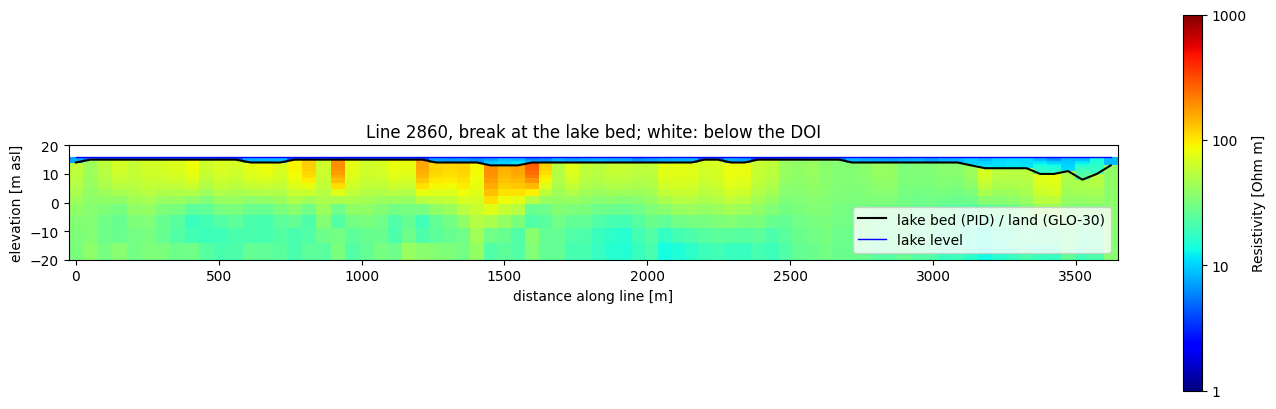

In [ ]:
dist = np.r_[0.0, np.cumsum(np.hypot(np.diff(x[selected]), np.diff(y[selected])))]
fig, ax = plt.subplots(figsize=(14, 5))
section(ax, dist, [results[i]["resistivities"] for i in selected], [np.cumsum(results[i]["thicknesses"]) for i in selected], top[selected],
        doi=[results[i]["doi"]["standard"] if results[i].get("doi") else np.nan for i in selected], base=BOTTOM * 1.2,
        cmap=plt.cm.jet, zmin=-20, zmax=20, scale=10, cbar_label="Resistivity [Ohm m]")
ax.plot(dist, surface[selected], color="k", lw=1.5, label="lake bed (PID) / land (GLO-30)")
ax.plot(dist, np.where(on_lake[selected], lake_level[selected], np.nan), color="b", lw=1, label="lake level")
ax.set_ylabel("elevation [m asl]"); ax.set_xlabel("distance along line [m]")
ax.set_title(f"Line {line}, {'break' if BED_BREAK else 'no break'} at the lake bed; white: below the DOI")
ax.legend(loc="lower right")
plt.tight_layout()

## Synthetic test: the inverted line as a lake model

The synthetic soundings are built on a real line of the survey, so that the test has the geometry and the noise of the field data:

- **Positions and lake bed**: the longest stretch on the lake (at least 1.5 m of water) of the line with the widest range of water depth (`SYN_LINE` sets another line), at most `N_SYN` of its stations spread evenly; their real positions and the real water depth (bathymetry and lake level). The bed is not smooth: the bathymetry has steps of 1 m.
- **Earth model**: thermally stratified water (7 Ohm m at the surface, 9 Ohm m below the thermocline at 10-22 m), a 0.5-3.5 m layer of conductive gyttja (3 Ohm m) on the lake bed, and below that the model that the field inversion finds at the station (these stations are inverted first), so the sediments and the basement are what the data say.
- **Data**: the forward response of that model in the gates that the real station has (the late gates are often missing), with the relative noise of every real gate (lognormal).

Every sounding is inverted with the field inversion code for
- **water**: a free resistivity in every water layer, one free water layer, or the water fixed at one known resistivity (only the sediments are inverted);
- **regularisation**: normal, none across the lake bed, or switched off completely.

The roughness matrix `getR` carries the smoothness constraint, so zeroing the weights of its rows (`_break.k = slice(None)`) switches the regularisation off; what is left is the 1e-4 damping on the diagonal. Without a penalty the full Gauss-Newton steps overshoot and the realistic noise cannot be fitted, so that case runs with step backtracking, a wide alpha search and 30 iterations, and is the slow one. With the water fixed there is no boundary at the lake bed to break, so 'no smoothing across the lake bed' is the same as 'normal'.

In [ ]:
N_SYN = 20                      # at most this many soundings in the synthetic line
SYN_LINE = None                 # line of the synthetic test; None: the line with the widest range of water depth
RHO_TOP, RHO_DEEP = 7.0, 9.0    # lake water [Ohm m]: surface water, and the more resistive water below the thermocline
THERMOCLINE = (10.0, 22.0)      # depth range of the transition [m]
GYTTJA = 3.0                    # [Ohm m]
ERROR_DEPTH = 30.0              # the model error is measured down to this depth below the gyttja [m]
RHO_LAKE = 7.0                  # the lake resistivity that is fixed in the 'fixed' inversions [Ohm m]
rng = np.random.default_rng(1)

# the true model on a fine grid: 0.5 m layers to 60 m depth, then geometric to 250 m (the last layer is the half-space)
edges_f = np.r_[0.0, np.arange(0.5, 60.01, 0.5), np.geomspace(61.0, 250.0, 40)]
thick_f = np.diff(edges_f)[:-1]
mid_f = 0.5 * (edges_f[:-1] + edges_f[1:])

# The soundings: the longest stretch of one line that is on the lake (at least 1.5 m of water), N_SYN of its stations spread evenly
def longest_run(ok):
    runs = [r for r in np.split(np.arange(len(ok)), np.flatnonzero(np.diff(ok.astype(int)) != 0) + 1) if ok[r[0]]]
    return max(runs, key=len) if runs else np.array([], dtype=int)

line_stations = {name: np.flatnonzero(stations["Line"].to_numpy() == name) for name in stations["Line"].unique()}
def depth_range(name):
    depth = water_depth[line_stations[name]]
    run = longest_run(np.isfinite(depth) & (depth >= 1.5))
    return np.percentile(depth[run], 95) - np.percentile(depth[run], 5) if len(run) >= 50 else -1.0
syn_line = str(SYN_LINE) if SYN_LINE is not None else max(line_stations, key=depth_range)
on_line = line_stations[syn_line]
run = on_line[longest_run(np.isfinite(water_depth[on_line]) & (water_depth[on_line] >= 1.5))]
run = np.array([i for i in run if fit_systems(i)])   # stations with data
sel = run[np.unique(np.linspace(0, len(run) - 1, min(N_SYN, len(run))).round().astype(int))]
N_SYN = len(sel)
t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=WORKERS) as pool:   # the field inversion of these stations gives the earth model below the lake bed
    field_fit = dict(zip(sel, pool.map(invert_station, sel)))
east, north = x[sel], y[sel]
xs = np.r_[0.0, np.cumsum(np.hypot(np.diff(east), np.diff(north)))]   # distance along the line [m]
depth_syn = water_depth[sel]                                          # the real water depth
gyttja_syn = np.clip(np.round(2 * (0.5 + 3.0 * depth_syn / 40.0)) / 2, 0.5, 3.5)   # gyttja on the lake bed, thicker in the deep part: 0.5 - 3.5 m
ZMIN = -10.0 * np.ceil((depth_syn.max() + gyttja_syn.max() + ERROR_DEPTH + 10.0) / 10.0)   # lowest depth drawn in the sections
SECTION_SCALE = float(np.clip(0.25 * xs[-1] / -ZMIN, 1.0, 10.0))      # vertical exaggeration that gives the sections a handy shape
print(f"{N_SYN} soundings along {xs[-1]:.0f} m of line {syn_line}; water depth {depth_syn.min():.1f} - {depth_syn.max():.1f} m (median {np.median(depth_syn):.1f} m); "
      f"field inversion {time.perf_counter() - t0:.0f} s")

def syn_section(ax, model, title="", **kwargs):
    """A synthetic model (N_SYN, len(mid_f)) on the fine grid as a section below the lake surface, with the lake bed (white)
    and the base of the gyttja (dashed)."""
    section(ax, xs, model, np.tile(edges_f[1:-1], (N_SYN, 1)), np.zeros(N_SYN), base=edges_f[-1],
            **{**dict(vmin=2, vmax=100, cmap=plt.cm.jet, zmin=ZMIN, scale=SECTION_SCALE, cbar=False, plot_title=title), **kwargs})
    ax.plot(xs, -depth_syn, color="w", lw=1.2)
    ax.plot(xs, -(depth_syn + gyttja_syn), color="k", lw=0.8, ls="--")
    ax.set_ylabel("depth below the lake surface [m]"); ax.set_xlabel("distance [m]"); ax.title.set_fontsize(9)

def shared_colorbar(fig, axes):
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=LogNorm(2, 100), cmap=plt.cm.jet), ax=axes, shrink=0.5, label="Resistivity [Ohm m]")
    cb.set_ticks([2, 5, 10, 20, 50, 100]); cb.set_ticklabels([2, 5, 10, 20, 50, 100]); cb.ax.minorticks_off()

def true_model(j):
    """The model of sounding j on the fine grid: stratified water above the real lake bed, gyttja on it, and below that the model that the field inversion found there."""
    wd, gt, real = depth_syn[j], gyttja_syn[j], field_fit[sel[j]]
    tops = np.r_[0.0, np.cumsum(real["thicknesses"])]
    centres = np.r_[0.5 * (tops[:-1] + tops[1:]), tops[-1] + real["thicknesses"][-1]]
    below = np.exp(np.interp(mid_f, centres, np.log(real["resistivities"])))
    s = np.clip((mid_f - THERMOCLINE[0]) / (THERMOCLINE[1] - THERMOCLINE[0]), 0.0, 1.0)
    water = RHO_TOP + (RHO_DEEP - RHO_TOP) * s * s * (3.0 - 2.0 * s)   # thermal stratification
    return np.select([mid_f < wd, mid_f < wd + gt], [water, GYTTJA], below)

# the real gates of every sounding and the relative noise of every real gate
sys_real = [fit_systems(i) for i in sel]
rel_real = [[s["noise"] / s["obs"] for s in systems] for systems in sys_real]

geo = dict(tx_size=tx_radius, geometry="circle_offset", rx_x=rx_offset, tx_height=meta["TxHeight"], rx_height=meta["RxHeight"],
           system_filter=H, transform="euler", verbose=False)
step_f, _ = pinv._step_functions(thick_f, t_step, tx_radius, "circle_offset", rx_offset, 0.0, 5, True, False, "euler", H, "exact",
                                 meta["TxHeight"], meta["RxHeight"])
rho_true, obs_syn = [], []
for j in range(N_SYN):
    rho_true.append(true_model(j))
    response = step_f(np.log(rho_true[-1]))
    obs_syn.append([s["M"] @ response * np.exp(r * rng.standard_normal(len(r))) for s, r in zip(sys_real[j], rel_real[j])])

def systems_of(j):
    """Sounding j: its real gates, with the synthetic data and the relative noise of the real data."""
    return [dict(M=s["M"], obs=o, noise=o * r) for s, o, r in zip(sys_real[j], obs_syn[j], rel_real[j])]

def invert_synthetic(j, water, rough, depth_error=0.0, **kwargs):
    """Sounding j. water: 'layers' (a free resistivity in every water layer), 'single' (one water layer, free) or
    'fixed' (the water is a known layer of RHO_LAKE, only the sediments are inverted).
    rough: 'smooth' (normal regularisation), 'bed' (none across the lake bed) or 'off' (all roughness weights zero).
    depth_error: relative error of the water depth that the inversion is given (the data are made with the true depth)."""
    wd = depth_syn[j] * (1.0 + depth_error)
    thick, k = grid(wd)
    all_systems = systems_of(j)
    if water == "layers":
        thicknesses, bed_row = thick, k
        systems = all_systems
        kwargs = dict(kwargs, t_step=t_step, **geo)
    elif water == "single":
        thicknesses, bed_row = np.r_[wd, thick[k + 1:]], 0
        systems = all_systems
        kwargs = dict(kwargs, t_step=t_step, **geo)
    else:
        thicknesses, bed_row = thick[k + 1:], None   # no boundary to break: the model starts at the lake bed
        step, jacobian = pinv._step_functions(np.r_[wd, thicknesses], t_step, tx_radius, "circle_offset", rx_offset, 0.0, 5, True, False,
                                              "euler", H, "exact", meta["TxHeight"], meta["RxHeight"])
        systems = [dict(forward=lambda lr, g=s["M"]: g @ step(np.r_[np.log(RHO_LAKE), lr]),
                        jacobian=lambda lr, g=s["M"]: g @ jacobian(np.r_[np.log(RHO_LAKE), lr])[:, 1:],
                        obs=s["obs"], noise=s["noise"]) for s in all_systems]
        kwargs = dict(kwargs, verbose=False)
    if rough == "off":   # without a roughness penalty the full Gauss-Newton steps overshoot: backtrack, and give the search room
        kwargs = {"step_backtrack": True, "alpha_steps": 12, "alpha_step": 0.5, "maxit": 30, **kwargs}
    _break.k = {"smooth": None, "bed": bed_row, "off": slice(None)}[rough]
    try:
        res = invert_joint(systems, thicknesses, np.full(thicknesses.size + 1, 30.0), **kwargs)
    finally:
        _break.k = None
    tops = np.r_[0.0, np.cumsum(thicknesses)]
    model = res["resistivities"]
    if water == "fixed":
        tops, model = np.r_[0.0, wd + tops], np.r_[RHO_LAKE, model]
    res["on_fine"] = model[np.searchsorted(tops, mid_f, side="right") - 1]   # the model on the grid of the truth
    return res

c:\WPy64-31180\python-3.11.8.amd64\Lib\site-packages\numpy\lib\nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,


270/270 inversions, elapsed 31:21, about 0:00 left    
 water regularisation  median_RMS converged  mean_abs_error_decades
layers            off        0.98     23/30                    0.48
single            off        1.05     14/30                    0.50
 fixed            off        0.99     21/30                    0.25
layers         smooth        0.99     27/30                    0.16
single         smooth        1.00     23/30                    0.20
 fixed         smooth        0.99     21/30                    0.21
layers            bed        0.99     27/30                    0.14
single            bed        1.00     19/30                    0.18
 fixed            bed        0.99     21/30                    0.21


Text(0.5, 1.02, 'Synthetic lake: white line = lake bed, dashed = base of the gyttja')

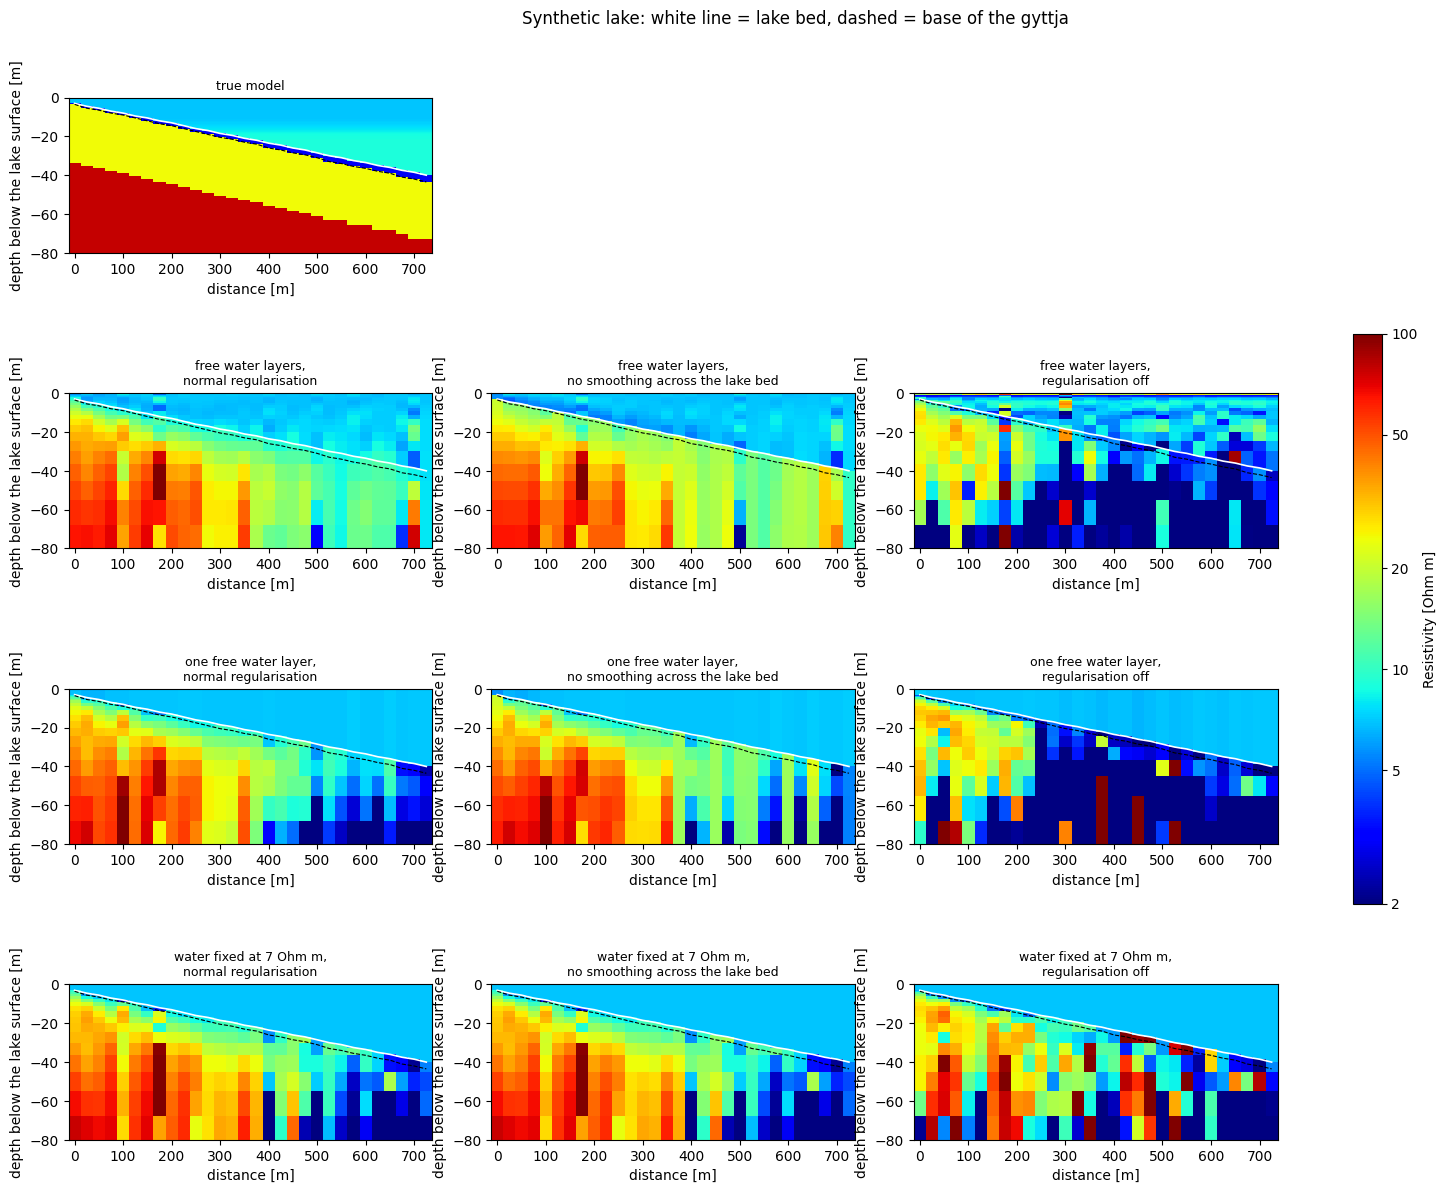

In [ ]:
from concurrent.futures import as_completed

variants = [(w, r) for r in ("off", "smooth", "bed") for w in ("layers", "single", "fixed")]   # the slow ones first
jobs = [(j, w, r) for w, r in variants for j in range(N_SYN)]
syn = {}
t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    futures = {pool.submit(invert_synthetic, *job): job for job in jobs}
    for n, fut in enumerate(as_completed(futures), start=1):
        syn[futures[fut]] = fut.result()
        elapsed = time.perf_counter() - t0
        left = elapsed / n * (len(jobs) - n)
        print(f"\r{n}/{len(jobs)} inversions, elapsed {int(elapsed) // 60}:{int(elapsed) % 60:02d}, about {int(left) // 60}:{int(left) % 60:02d} left   ", end="")

inside = lambda j: mid_f < depth_syn[j] + gyttja_syn[j] + ERROR_DEPTH   # down to ERROR_DEPTH below the gyttja
table = []
for w, r in variants:
    res = [syn[(j, w, r)] for j in range(N_SYN)]
    err = [np.mean(np.abs(np.log10(x["on_fine"]) - np.log10(rho_true[j]))[inside(j)]) for j, x in enumerate(res)]
    table.append(dict(water=w, regularisation=r, median_RMS=np.median([x["rms"] for x in res]),
                      converged=f"{sum(x['converged'] for x in res)}/{N_SYN}", mean_abs_error_decades=np.mean(err)))
print()
print(pd.DataFrame(table).round(2).to_string(index=False))

fig, axes = plt.subplots(4, 3, figsize=(16, 12))
for ax in axes[0, 1:]:
    ax.set_visible(False)
water_title = {"layers": "free water layers", "single": "one free water layer", "fixed": f"water fixed at {RHO_LAKE:g} Ohm m"}
panels = [(axes[0, 0], "true model", np.array(rho_true))]
for (w, r), ax in zip([(w, r) for w in ("layers", "single", "fixed") for r in ("smooth", "bed", "off")], axes[1:].flat):
    panels.append((ax, f"{water_title[w]},\n{dict(smooth='normal regularisation', bed='no smoothing across the lake bed', off='regularisation off')[r]}",
                   np.array([syn[(j, w, r)]["on_fine"] for j in range(N_SYN)])))
for ax, title, model in panels:
    syn_section(ax, model, title)
shared_colorbar(fig, axes)
fig.suptitle("Synthetic lake: white line = lake bed, dashed = base of the gyttja", y=1.02)

### A wrong lake depth

The water depth comes from the bathymetry and the lake level, so it has an error. Here the data are made with the true depth and inverted with a depth that is 10 % too shallow or too deep (the layer boundary and the water layer are put at the wrong depth). Slow, regularisation-off runs are left out.

360/360 inversions, elapsed 25:08, about 0:00 left    
 water regularisation depth_error  median_RMS converged  error_water  error_below_bed
layers            bed         +0%        0.99     27/30         0.06             0.20
layers            bed        -10%        0.99     27/30         0.07             0.23
layers            bed        +10%        0.99     27/30         0.05             0.15
single            bed         +0%        1.00     19/30         0.04             0.30
single            bed        -10%        0.99     22/30         0.04             0.32
single            bed        +10%        1.00     20/30         0.03             0.30
 fixed            bed         +0%        0.99     21/30         0.03             0.36
 fixed            bed        -10%        0.99     22/30         0.03             0.35
 fixed            bed        +10%        0.99     21/30         0.03             0.36
layers         smooth         +0%        0.99     27/30         0.04             0.26

Text(0.5, 1.02, 'Water depth given to the inversion with an error (white: true lake bed, magenta dashed: the depth used)')

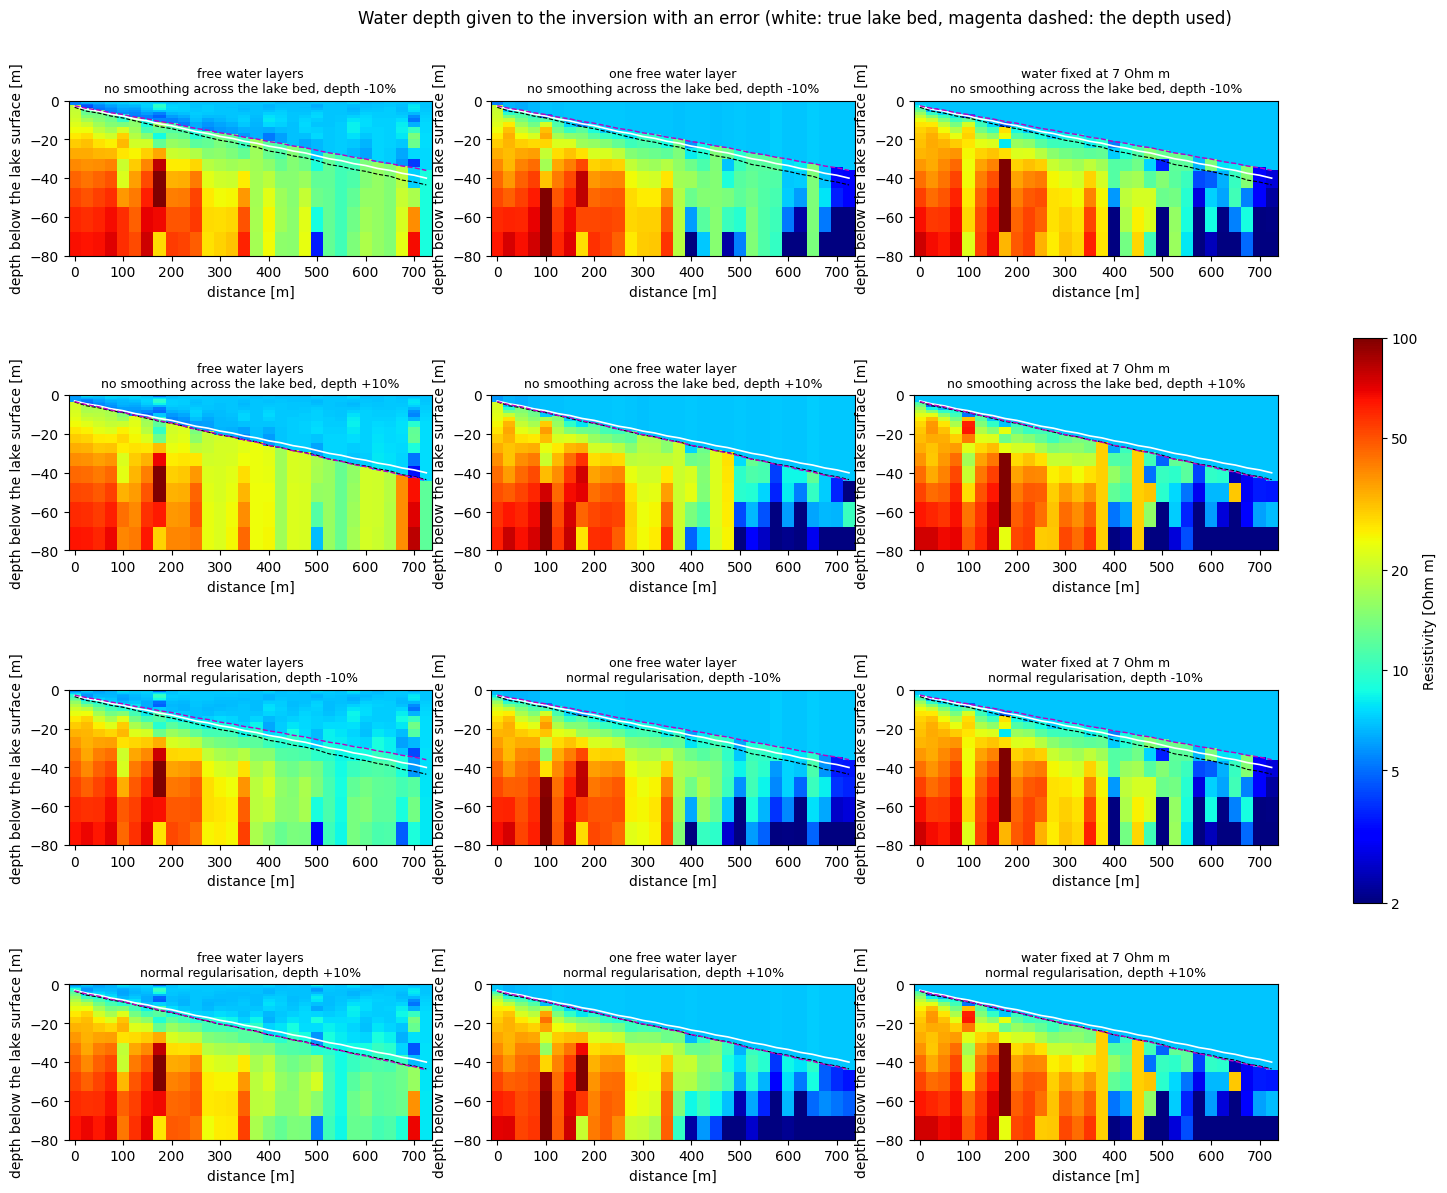

In [ ]:
ERRORS = (-0.10, 0.10)   # relative error of the water depth given to the inversion
all_syn = {(j, w, r, 0.0): v for (j, w, r), v in syn.items()}
jobs = [(j, w, r, e) for e in ERRORS for r in ("bed", "smooth") for w in ("layers", "single", "fixed") for j in range(N_SYN)]
t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    futures = {pool.submit(invert_synthetic, *job): job for job in jobs}
    for n, fut in enumerate(as_completed(futures), start=1):
        all_syn[futures[fut]] = fut.result()
        elapsed = time.perf_counter() - t0
        left = elapsed / n * (len(jobs) - n)
        print(f"\r{n}/{len(jobs)} inversions, elapsed {int(elapsed) // 60}:{int(elapsed) % 60:02d}, about {int(left) // 60}:{int(left) % 60:02d} left   ", end="")

def stats(w, r, e):
    res = [all_syn[(j, w, r, e)] for j in range(N_SYN)]
    err = lambda sel: np.mean([np.mean(np.abs(np.log10(x["on_fine"]) - np.log10(rho_true[j]))[sel(j)]) for j, x in enumerate(res)])
    return dict(water=w, regularisation=r, depth_error=f"{e:+.0%}", median_RMS=np.median([x["rms"] for x in res]),
                converged=f"{sum(x['converged'] for x in res)}/{N_SYN}",
                error_water=err(lambda j: mid_f < depth_syn[j]),
                error_below_bed=err(lambda j: (mid_f >= depth_syn[j]) & (mid_f < depth_syn[j] + gyttja_syn[j] + ERROR_DEPTH)))

print()
print(pd.DataFrame([stats(w, r, e) for r in ("bed", "smooth") for w in ("layers", "single", "fixed") for e in (0.0, *ERRORS)]).round(2).to_string(index=False))

fig, axes = plt.subplots(4, 3, figsize=(16, 12))
for row, (e, r) in enumerate([(e, r) for r in ("bed", "smooth") for e in ERRORS]):
    for col, w in enumerate(("layers", "single", "fixed")):
        ax = axes[row, col]
        syn_section(ax, np.array([all_syn[(j, w, r, e)]["on_fine"] for j in range(N_SYN)]),
                    f"{water_title[w]}\n{dict(smooth='normal regularisation', bed='no smoothing across the lake bed')[r]}, depth {e:+.0%}")
        ax.plot(xs, -depth_syn * (1 + e), color="m", lw=1.0, ls="--")
shared_colorbar(fig, axes)
fig.suptitle("Water depth given to the inversion with an error (white: true lake bed, magenta dashed: the depth used)", y=1.02)

### Sensitivity

The sensitivity matrix of a sounding is the Jacobian of its gates with respect to the log-resistivity of every layer, divided by the noise of the gate, evaluated at the true model on the fine grid. The sensitivity of a layer is the length of its column, per metre of layer thickness. The matrices show which gates see which depths (|J| in decades; the lake bed and the base of the gyttja are marked), and the section shows how the sensitivity to each layer changes along the sloping line.

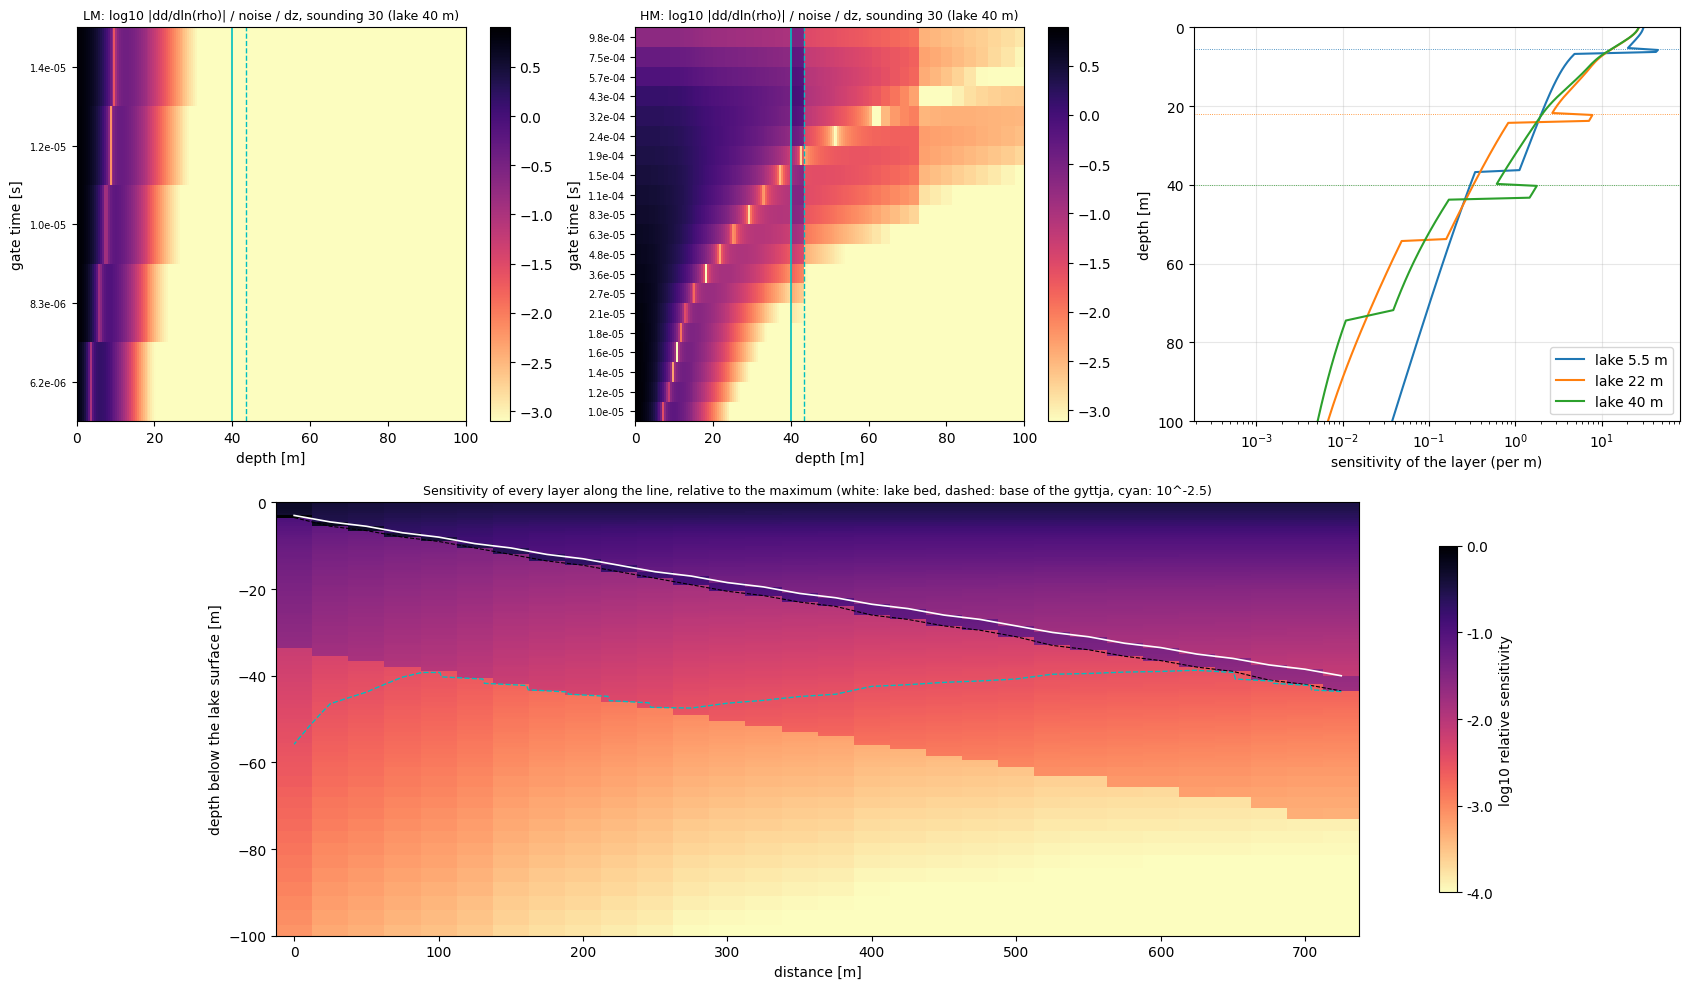

In [ ]:
step_f, jac_f = pinv._step_functions(thick_f, t_step, tx_radius, "circle_offset", rx_offset, 0.0, 5, True, False, "euler", H, "exact",
                                     meta["TxHeight"], meta["RxHeight"])
dz = np.diff(edges_f)
sens_matrix, sens = [], []   # per sounding: {moment: (n_gates, n_layers)} and the sensitivity of every layer
for j in range(N_SYN):
    log_rho = np.log(rho_true[j])
    response, jacobian = step_f(log_rho), jac_f(log_rho)
    Jn = {s["moment"]: (s["M"] @ jacobian) / (r * (s["M"] @ response))[:, None] for s, r in zip(sys_real[j], rel_real[j])}   # the gates of the real station
    sens_matrix.append(Jn)
    sens.append(np.sqrt(sum((Jn[m] ** 2).sum(axis=0) for m in Jn)) / dz)
sens = np.array(sens)

js = int(np.argmax(depth_syn))   # the sounding of the matrices: the deepest lake
fig = plt.figure(figsize=(17, 10))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.1])
for c, m in enumerate(("LM", "HM")):
    if m not in sens_matrix[js]:
        continue
    ax = fig.add_subplot(gs[0, c])
    times = [s["times"] for s in sys_real[js] if s["moment"] == m][0]
    mag = np.log10(np.abs(sens_matrix[js][m]) / dz + 1e-30)
    im = ax.pcolormesh(edges_f, np.arange(len(times) + 1), mag, cmap="magma_r", vmin=mag.max() - 4, vmax=mag.max(), shading="flat")
    ax.axvline(depth_syn[js], color="c", lw=1.2); ax.axvline(depth_syn[js] + gyttja_syn[js], color="c", lw=1.0, ls="--")
    ax.set_xlim(0, 100); ax.set_yticks(np.arange(len(times)) + 0.5); ax.set_yticklabels([f"{t:.1e}" for t in times], fontsize=7)
    ax.set_xlabel("depth [m]"); ax.set_ylabel("gate time [s]"); ax.set_title(f"{m}: log10 |dd/dln(rho)| / noise / dz, sounding {js + 1} (lake {depth_syn[js]:g} m)", fontsize=9)
    fig.colorbar(im, ax=ax)
ax = fig.add_subplot(gs[0, 2])
for j in np.argsort(depth_syn)[[0, N_SYN // 2, -1]]:   # the shallowest, a median and the deepest lake
    ax.semilogx(sens[j], mid_f, label=f"lake {depth_syn[j]:.1f} m")
    ax.axhline(depth_syn[j], color=ax.lines[-1].get_color(), lw=0.6, ls=":")
ax.set_ylim(100, 0); ax.set_xlabel("sensitivity of the layer (per m)"); ax.set_ylabel("depth [m]"); ax.legend(); ax.grid(alpha=0.3)
ax = fig.add_subplot(gs[1, :])
rel_sens = np.log10(sens / sens.max())
syn_section(ax, rel_sens, "Sensitivity of every layer along the line, relative to the maximum (white: lake bed, dashed: base of the gyttja, cyan: 10^-2.5)",
            log=False, vmin=-4, vmax=0, cmap=plt.cm.magma_r, zmin=ZMIN - 20, cbar=True, cbar_label="log10 relative sensitivity")
ax.contour(xs, -mid_f, rel_sens.T, levels=[-2.5], colors="c", linewidths=1)
ax.set_ylabel("depth below the lake surface [m]")
plt.tight_layout()

### Spatially constrained inversion (SCI)

The 30 soundings of the sloping lake are also inverted together with `invert_sci` (fast SCI, as in InverTEM): vertical constraints between adjacent layers and lateral constraints between neighbouring soundings, every constraint "the difference in ln(rho) is 0 +/- sigma" with sigma = ln(factor) (vertical factor 3, lateral factor 1.5). SCI needs one layer grid for all soundings, so the grid cannot follow the lake bed: the lake bed falls inside a layer, at most half a layer from the nearest boundary.

- **SCI**: the default factors, iterated until the model stops improving; **SCI, stops at median RMS 1**: the fast variant that stops as soon as the median sounding fits; **SCI adaptive**: the tightest constraints that fit (the factors are raised to powers between 0.25 and 4 until the total RMS is 1; at most 10 iterations per run).
- **vertical constraint off** (factor 100): only the lateral constraints stabilise the soundings; **all constraints off**: both factors 100.
- **no vertical constraint across the lake bed**: the vertical constraint is dropped at the layer boundary nearest to the lake bed (`vertical_break`), with the true depth and with a depth that is 10 % too shallow or too deep.

8/8 SCI runs, elapsed 23:15   
                                  inversion  median_RMS converged  runs     factors  error_water  error_below_bed
                                        SCI        0.90     25/30   1.0     3 / 1.5         0.04             0.19
                 SCI, stops at median RMS 1        0.99     17/30   1.0     3 / 1.5         0.04             0.18
                               SCI adaptive        0.94     22/30   3.0 1.73 / 1.22         0.03             0.18
                    vertical constraint off        0.88     26/30   1.0   100 / 1.5         0.09             0.24
 no vertical constraint across the lake bed        0.90     25/30   1.0     3 / 1.5         0.05             0.18
                       ... lake depth -10 %        0.90     25/30   1.0     3 / 1.5         0.05             0.19
                       ... lake depth +10 %        0.90     25/30   1.0     3 / 1.5         0.04             0.19
                        all constraints off        0.81  

Text(0.5, 1.02, 'SCI of the synthetic lake (white: lake bed, dashed: base of the gyttja, magenta dashed: the lake depth given to the inversion)')

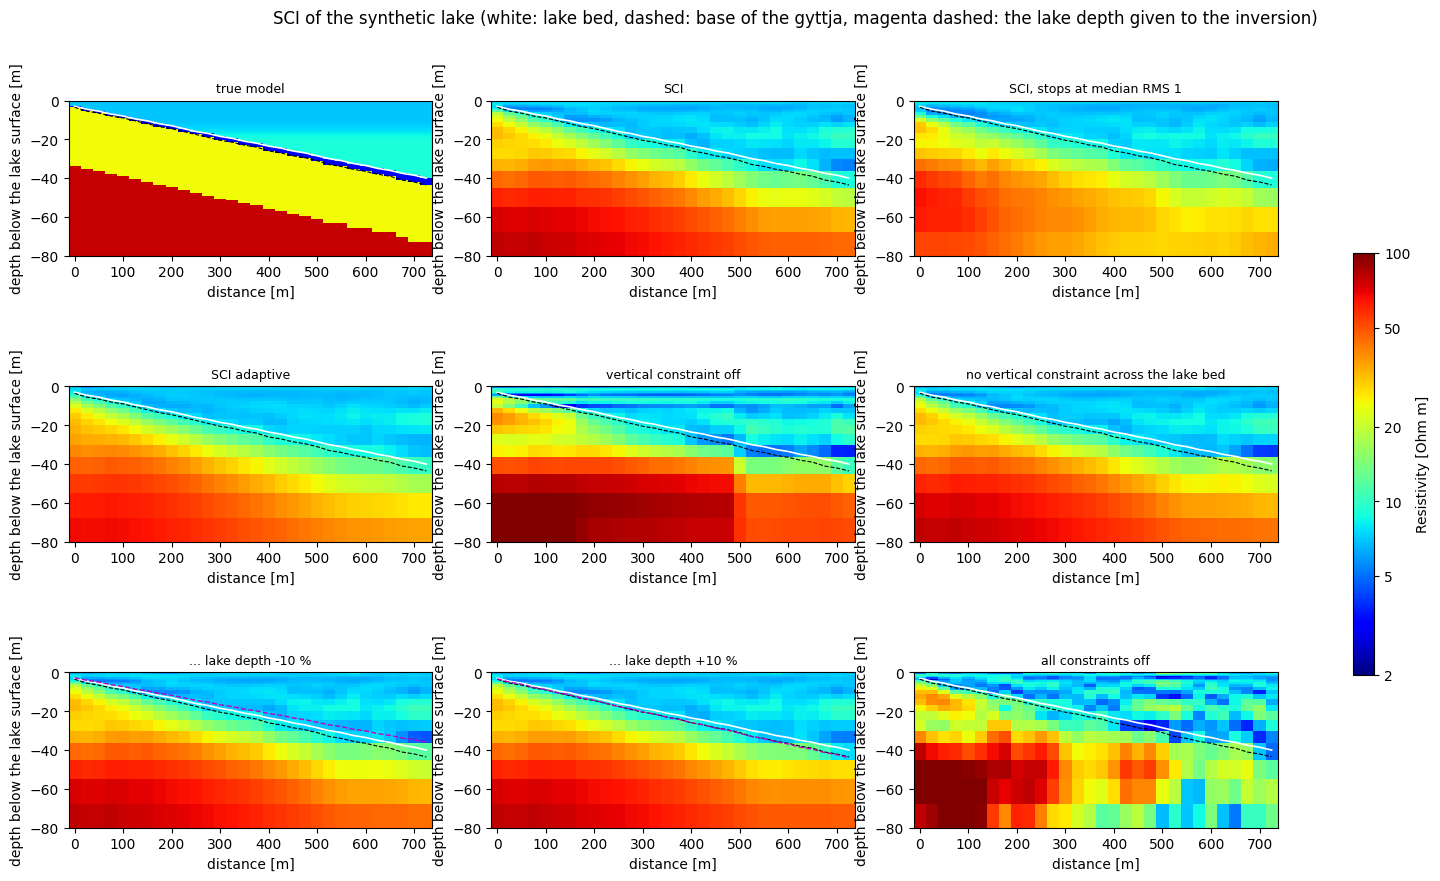

In [ ]:
from concurrent.futures import as_completed

thick_sci, _ = grid(np.nan)   # one layer grid for every sounding: 24 layers and a half-space, 1 - 100 m
tops_sci = np.r_[0.0, np.cumsum(thick_sci)]
stations_sci = [systems_of(j) for j in range(N_SYN)]
bed_layer = lambda e: np.array([np.argmin(abs(tops_sci[1:] - wd * (1 + e))) for wd in depth_syn])   # the layer boundary nearest to the lake bed

sci_error = {"... lake depth -10 %": -0.10, "... lake depth +10 %": 0.10}
sci_variants = {
    "SCI": {},
    "SCI, stops at median RMS 1": dict(stop_at_half_fit=True),
    "SCI adaptive": dict(adaptive=True, maxit=10),
    "vertical constraint off": dict(vertical_factor=100.0),
    "no vertical constraint across the lake bed": dict(vertical_break=bed_layer(0.0)),
    **{name: dict(vertical_break=bed_layer(e)) for name, e in sci_error.items()},
    "all constraints off": dict(vertical_factor=100.0, lateral_factor=100.0),
}

def run_sci(options):   # every run goes on until it stops improving, unless it is asked to stop at median RMS 1
    return pinv.invert_sci(stations_sci, thick_sci, t_step=t_step, x=east, y=north, **geo, **{"stop_at_half_fit": False, **options})

sci = {}
t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=len(sci_variants)) as pool:
    futures = {pool.submit(run_sci, options): name for name, options in sci_variants.items()}
    for n, fut in enumerate(as_completed(futures), start=1):
        sci[futures[fut]] = fut.result()
        elapsed = time.perf_counter() - t0
        print(f"\r{n}/{len(futures)} SCI runs, elapsed {int(elapsed) // 60}:{int(elapsed) % 60:02d}   ", end="")
sci = {name: sci[name] for name in sci_variants}

sci_fine = {name: np.array([r["resistivities"][j][np.searchsorted(tops_sci, mid_f, side="right") - 1] for j in range(N_SYN)]) for name, r in sci.items()}
def sci_error_of(model, sel):
    return np.mean([np.mean(np.abs(np.log10(model[j]) - np.log10(rho_true[j]))[sel(j)]) for j in range(N_SYN)])
in_water = lambda j: mid_f < depth_syn[j]
below_bed = lambda j: (mid_f >= depth_syn[j]) & (mid_f < depth_syn[j] + gyttja_syn[j] + ERROR_DEPTH)
table = [dict(inversion=name, median_RMS=np.median(r["rms"]), converged=f"{int(r['converged'].sum())}/{N_SYN}", runs=len(r["runs"]),
              factors=f"{r['vertical_factor']:.3g} / {r['lateral_factor']:.3g}", error_water=sci_error_of(sci_fine[name], in_water),
              error_below_bed=sci_error_of(sci_fine[name], below_bed)) for name, r in sci.items()]
for w, r in (("layers", "bed"), ("layers", "smooth")):   # the single-sounding inversions above, for comparison
    s = stats(w, r, 0.0)
    table.append(dict(inversion=f"single soundings, {water_title[w]}, {r}", median_RMS=s["median_RMS"], converged=s["converged"],
                      error_water=s["error_water"], error_below_bed=s["error_below_bed"]))
print()
print(pd.DataFrame(table).round(2).to_string(index=False))

fig, axes = plt.subplots(3, 3, figsize=(16, 9))
panels = [("true model", np.array(rho_true))] + list(sci_fine.items())
for ax in axes.flat[len(panels):]:
    ax.set_visible(False)
for ax, (title, model) in zip(axes.flat, panels):
    syn_section(ax, model, title)
    if title in sci_error:
        ax.plot(xs, -depth_syn * (1 + sci_error[title]), color="m", lw=1.0, ls="--")
shared_colorbar(fig, axes)
fig.suptitle("SCI of the synthetic lake (white: lake bed, dashed: base of the gyttja, magenta dashed: the lake depth given to the inversion)", y=1.02)